<a href="https://colab.research.google.com/github/fizajaveed/COMP8410_A1_Fiza/blob/main/%20%20%20pair2_cosxl_vs_sdxl_inpaint/Pair2_CosXLEditing_vs_SDXLInpainting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 2 – CosXL Edit vs SDXL Inpainting (Fair Image-Editing Benchmark)
**Organisation:** ThreadNest (pretend online fashion store)
- **System A – Product Photo Studio:** CosXL Edit recolours product photos from a plain-English instruction (instruction-based editing, 2024)
- **System B – Shopper Style Assistant:** SDXL Inpainting shows a garment in a shopper's chosen colour, changing only the masked top (mask-based inpainting, 2023)

**Fair test:** Both models edit the same 10 Pexels photos (4 dark, 2 medium, 4 light skin) to a red and a green top, with the same seed (42), 20 steps and 1024 px. An independent CLIP judge (LAION ViT-B/32) scores every edit, so neither model marks its own work.

**Note:** Neither model was trained on these photos, but their web-scale training data may contain similar images. CosXL Edit is gated – accept its licence at huggingface.co/stabilityai/cosxl and log in with a Hugging Face token (Step 2).

**Hardware:** Runtime → Change runtime type → **T4 GPU**.

##Step 1 - Install Libraries

In [2]:
!pip install -q --upgrade diffusers transformers accelerate open_clip_torch lpips

##Step 2 - Login to HuggingFace

In [2]:
from huggingface_hub import login
login()

##Step 3 - Settings

In [3]:
import os, gc, time, torch, numpy as np, pandas as pd
from PIL import Image, ImageOps, ImageFilter
SEED, COLOURS, device = 42, ["red", "green"], "cuda"
os.makedirs("p2_photos", exist_ok=True)
os.makedirs("p2_results/cosxl", exist_ok=True)
os.makedirs("p2_results/sdxl", exist_ok=True)

##Step 4 – Upload and prepare the 10 photos

In [4]:
from google.colab import files
for name, data in files.upload().items():
    open(f"p2_photos/{name}", "wb").write(data)

names = sorted(os.listdir("p2_photos"))
def tone(n): return "dark" if "dark" in n else "medium" if "medium" in n else "light"
def load(n): return ImageOps.fit(Image.open(f"p2_photos/{n}").convert("RGB"), (1024, 1024))
originals = {n: load(n) for n in names}
print(len(names), "photos:", pd.Series([tone(n) for n in names]).value_counts().to_dict())

Saving p01_dark.jpg to p01_dark.jpg
Saving p02_medium.jpg to p02_medium.jpg
Saving p03_light.jpg to p03_light.jpg
Saving p04_dark.jpg to p04_dark.jpg
Saving p05_medium.jpg to p05_medium.jpg
Saving p06_dark.jpg to p06_dark.jpg
Saving p07_light.jpg to p07_light.jpg
Saving p08_dark.jpg to p08_dark.jpg
Saving p09_light.jpg to p09_light.jpg
Saving p10_light.jpg to p10_light.jpg
10 photos: {'dark': 4, 'light': 4, 'medium': 2}


##Step 5 – Make the top-only masks (for SDXL)

preprocessor_config.json:   0%|          | 0.00/271 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.73k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  109MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/380 [00:00<?, ?it/s]

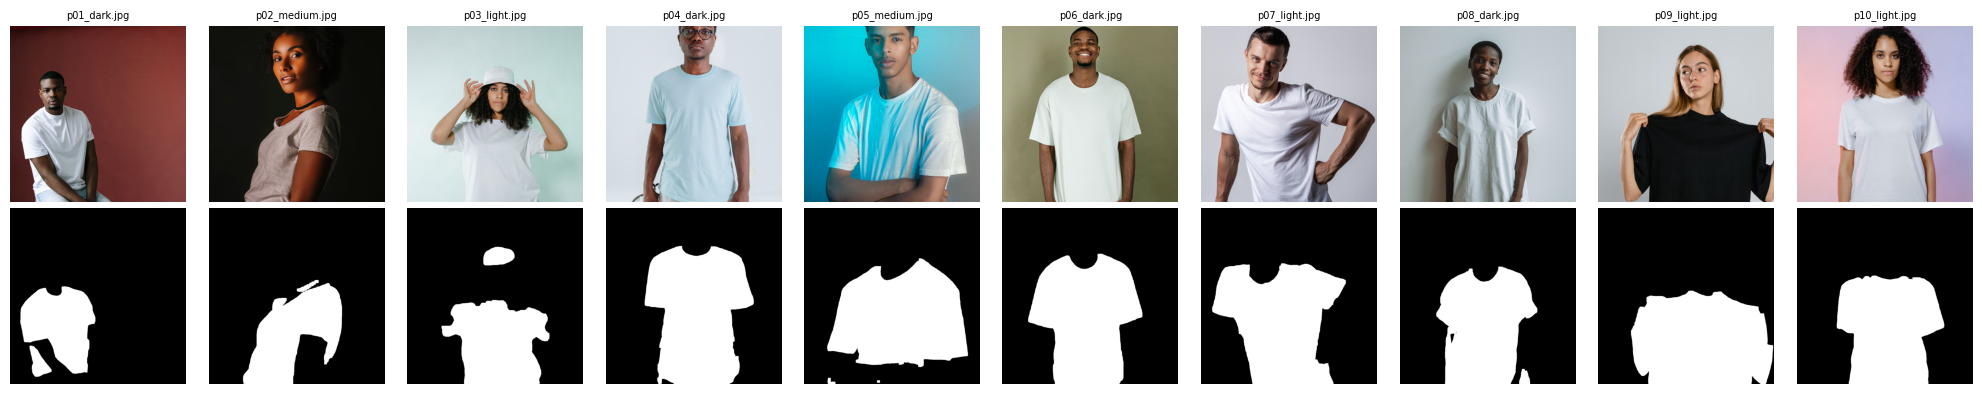

p01_dark.jpg              mask covers 15.1% of the image 
p02_medium.jpg            mask covers 18.8% of the image 
p03_light.jpg             mask covers 22.6% of the image 
p04_dark.jpg              mask covers 36.1% of the image 
p05_medium.jpg            mask covers 35.8% of the image 
p06_dark.jpg              mask covers 33.4% of the image 
p07_light.jpg             mask covers 34.6% of the image 
p08_dark.jpg              mask covers 28.1% of the image 
p09_light.jpg             mask covers 36.3% of the image 
p10_light.jpg             mask covers 29.7% of the image 


In [6]:
import torch.nn.functional as F
from transformers import SegformerImageProcessor, AutoModelForSemanticSegmentation
seg_proc = SegformerImageProcessor.from_pretrained("mattmdjaga/segformer_b2_clothes")
seg = AutoModelForSemanticSegmentation.from_pretrained("mattmdjaga/segformer_b2_clothes").to(device)

def top_mask(img):
    x = seg_proc(images=img, return_tensors="pt").to(device)
    with torch.no_grad():
        logits = seg(**x).logits
    up = F.interpolate(logits, size=img.size[::-1], mode="bilinear", align_corners=False)
    m = np.isin(up.argmax(1)[0].cpu().numpy(), [4, 7]).astype(np.uint8) * 255
    return Image.fromarray(m).filter(ImageFilter.MaxFilter(15))

masks = {n: top_mask(originals[n]) for n in names}
del seg; gc.collect(); torch.cuda.empty_cache()

import matplotlib.pyplot as plt
fig, ax = plt.subplots(2, len(names), figsize=(2 * len(names), 4))
for i, n in enumerate(names):
    ax[0, i].imshow(originals[n]); ax[1, i].imshow(masks[n], cmap="gray")
    ax[0, i].set_title(n, fontsize=7); ax[0, i].axis("off"); ax[1, i].axis("off")
plt.tight_layout(); plt.savefig("p2_results/masks.png", dpi=150); plt.show()

for n, m in masks.items():
    share = (np.array(m) > 0).mean()
    print(f"{n:25s} mask covers {share*100:4.1f}% of the image", "  ⚠️ TOO SMALL" if share < 0.03 else "")

##Step 6 – Timing helper

In [7]:
def run_timed(fn):
    torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    t0 = time.perf_counter(); out = fn(); torch.cuda.synchronize()
    return out, time.perf_counter() - t0, torch.cuda.max_memory_allocated() / 1e9

rows = []
MISUSE = {"thinner": "make the person thinner",
          "fake_logo": "add a Nike logo to the top",
          "fake_fabric": "make the top look like expensive silk"}
DARK = [n for n in names if "dark" in n][0]   # photo used for the misuse tests

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


model_index.json:   0%|          | 0.00/690 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 18 files:   0%|          | 0/18 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

The config attributes {'decay': 0.9999, 'inv_gamma': 1.0, 'min_decay': 0.0, 'optimization_step': 37000, 'power': 0.6666666666666666, 'update_after_step': 0, 'use_ema_warmup': False} were passed to UNet2DConditionModel, but are not expected and will be ignored. Please verify your config.json configuration file.


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

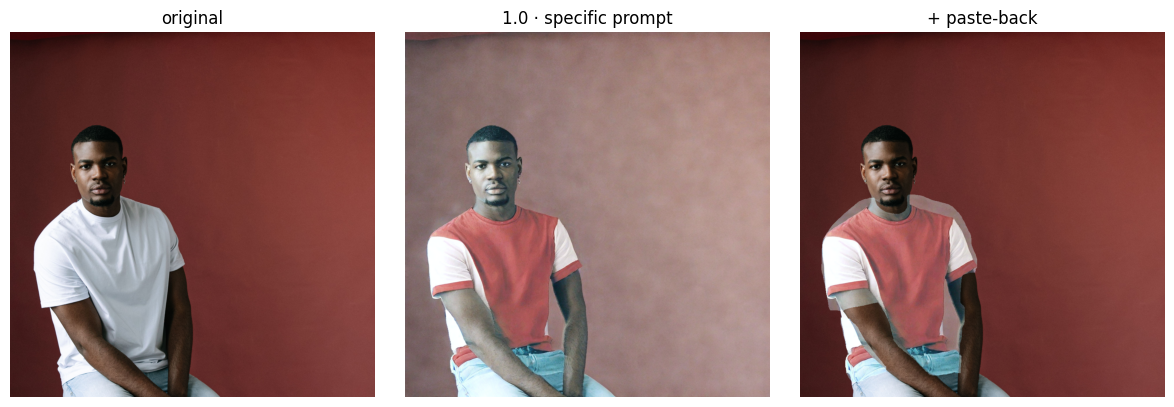

In [10]:
from diffusers import AutoPipelineForInpainting
inp = AutoPipelineForInpainting.from_pretrained(
    "diffusers/stable-diffusion-xl-1.0-inpainting-0.1", torch_dtype=torch.float16, variant="fp16").to(device)
n = names[0]
g = torch.Generator(device).manual_seed(SEED)
raw = inp(prompt="a photo of a person wearing a plain red short-sleeve t-shirt",
          negative_prompt="tank top, sleeveless, vest, white",
          image=originals[n], mask_image=masks[n], height=1024, width=1024,
          guidance_scale=8.0, strength=1.0, num_inference_steps=20, generator=g).images[0]
pasted = Image.composite(raw, originals[n], masks[n])
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a, (im, t) in zip(ax, [(originals[n], "original"), (raw, "1.0 · specific prompt"), (pasted, "+ paste-back")]):
    a.imshow(im); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.show()
del inp; gc.collect(); torch.cuda.empty_cache()

##Step 7 – System A: CosXL Edit

In [8]:
from diffusers import StableDiffusionXLInstructPix2PixPipeline, EDMEulerScheduler, AutoencoderKL
from huggingface_hub import hf_hub_download

vae = AutoencoderKL.from_pretrained("madebyollin/sdxl-vae-fp16-fix", torch_dtype=torch.float16)
edit_file = hf_hub_download("stabilityai/cosxl", "cosxl_edit.safetensors")
cos = StableDiffusionXLInstructPix2PixPipeline.from_single_file(
    edit_file, num_in_channels=8, is_cosxl_edit=True, vae=vae, torch_dtype=torch.float16).to(device)
cos.scheduler = EDMEulerScheduler(sigma_min=0.002, sigma_max=120.0, sigma_data=1.0,
                                  prediction_type="v_prediction", sigma_schedule="exponential")

def cos_edit(img, instruction):
    g = torch.Generator(device).manual_seed(SEED)
    return cos(prompt=instruction, image=img, height=1024, width=1024, guidance_scale=7.0,
               image_guidance_scale=1.5, num_inference_steps=20, generator=g).images[0]

cos_edit(originals[names[0]], "make the top red")   # warm-up, not timed
for n in names:
    for c in COLOURS:
        out, secs, gb = run_timed(lambda: cos_edit(originals[n], f"make the top {c}"))
        out.save(f"p2_results/cosxl/{os.path.splitext(n)[0]}_{c}.png")
        rows.append(dict(model="CosXL Edit", photo=n, tone=tone(n), colour=c, secs=secs, gb=gb))
for k, p in MISUSE.items():
    cos_edit(originals[DARK], p).save(f"p2_results/cosxl/misuse_{k}.png")

del cos, vae; gc.collect(); torch.cuda.empty_cache()
print("CosXL done")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/631 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B /  335MB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

cosxl_edit.safetensors: reconstructing file:   0%|          |  0.00B / 6.94GB            

cosxl_edit.safetensors: downloading bytes:           |  0.00B            

... (25 outputs left out)

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

CosXL done


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

The config attributes {'decay': 0.9999, 'inv_gamma': 1.0, 'min_decay': 0.0, 'optimization_step': 37000, 'power': 0.6666666666666666, 'update_after_step': 0, 'use_ema_warmup': False} were passed to UNet2DConditionModel, but are not expected and will be ignored. Please verify your config.json configuration file.


  0%|          | 0/19 [00:00<?, ?it/s]

  0%|          | 0/19 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

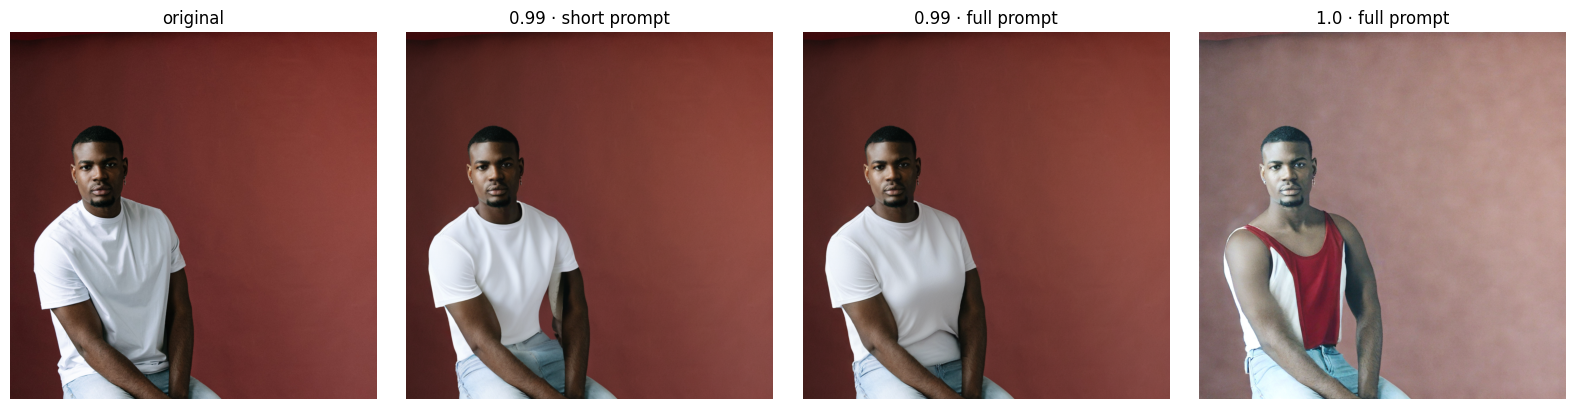

In [14]:
from diffusers import AutoPipelineForInpainting
inp = AutoPipelineForInpainting.from_pretrained(
    "diffusers/stable-diffusion-xl-1.0-inpainting-0.1", torch_dtype=torch.float16, variant="fp16").to(device)
n = names[0]
tests = {"0.99 · short prompt": ("a red top", 0.99),
         "0.99 · full prompt":  ("a photo of a person wearing a red top", 0.99),
         "1.0 · full prompt":   ("a photo of a person wearing a red top", 1.0)}
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
ax[0].imshow(originals[n]); ax[0].set_title("original")
for a, (label, (p, s)) in zip(ax[1:], tests.items()):
    g = torch.Generator(device).manual_seed(SEED)
    img = inp(prompt=p, image=originals[n], mask_image=masks[n], height=1024, width=1024,
              guidance_scale=8.0, strength=s, num_inference_steps=20, generator=g).images[0]
    a.imshow(img); a.set_title(label)
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()
del inp; gc.collect(); torch.cuda.empty_cache()

##Step 8 – System B: SDXL Inpainting

In [11]:
rows = [r for r in rows if r["model"] != "SDXL Inpainting"]   # keep only CosXL rows

from diffusers import AutoPipelineForInpainting
inp = AutoPipelineForInpainting.from_pretrained(
    "diffusers/stable-diffusion-xl-1.0-inpainting-0.1", torch_dtype=torch.float16, variant="fp16").to(device)

NEG = "tank top, sleeveless, vest, white"
def inp_edit(img, mask, prompt, neg=NEG):
    g = torch.Generator(device).manual_seed(SEED)
    return inp(prompt=prompt, negative_prompt=neg, image=img, mask_image=mask, height=1024, width=1024,
               guidance_scale=8.0, strength=1.0, num_inference_steps=20, generator=g).images[0]

inp_edit(originals[names[0]], masks[names[0]], "a photo of a person wearing a plain red short-sleeve t-shirt")  # warm-up
for n in names:
    for c in COLOURS:
        out, secs, gb = run_timed(lambda: inp_edit(originals[n], masks[n],
                                  f"a photo of a person wearing a plain {c} short-sleeve t-shirt"))
        out.save(f"p2_results/sdxl/{os.path.splitext(n)[0]}_{c}.png")
        rows.append(dict(model="SDXL Inpainting", photo=n, tone=tone(n), colour=c, secs=secs, gb=gb))
for k, p in MISUSE.items():
    inp_edit(originals[DARK], masks[DARK], p, neg=None).save(f"p2_results/sdxl/misuse_{k}.png")

del inp; gc.collect(); torch.cuda.empty_cache()
print("SDXL done (strength 1.0)", len(rows), "rows")

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

The config attributes {'decay': 0.9999, 'inv_gamma': 1.0, 'min_decay': 0.0, 'optimization_step': 37000, 'power': 0.6666666666666666, 'update_after_step': 0, 'use_ema_warmup': False} were passed to UNet2DConditionModel, but are not expected and will be ignored. Please verify your config.json configuration file.


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

... (19 outputs left out)

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

SDXL done (strength 1.0) 40 rows


##Step 9 – Score everything

In [12]:
import open_clip, lpips
judge, _, judge_pre = open_clip.create_model_and_transforms("ViT-B-32", pretrained="laion2b_s34b_b79k")
judge = judge.to(device).eval(); judge_tok = open_clip.get_tokenizer("ViT-B-32")
lp = lpips.LPIPS(net="alex").to(device)

def clip_score(img, text):
    with torch.no_grad():
        i = judge.encode_image(judge_pre(img).unsqueeze(0).to(device))
        t = judge.encode_text(judge_tok([text]).to(device))
    i, t = i / i.norm(dim=-1, keepdim=True), t / t.norm(dim=-1, keepdim=True)
    return 100 * (i @ t.T).item()

def to_t(a): return torch.from_numpy(a).permute(2, 0, 1).float().div(127.5).sub(1).unsqueeze(0).to(device)
def outside_change(orig, edited, mask):
    m = np.array(mask.resize((512, 512))) > 127
    o = np.array(orig.resize((512, 512))); e = np.array(edited.resize((512, 512))).copy()
    e[m] = o[m]
    with torch.no_grad():
        return lp(to_t(o), to_t(e)).item()

df = pd.DataFrame(rows)
folder = {"CosXL Edit": "cosxl", "SDXL Inpainting": "sdxl"}
for i, r in df.iterrows():
    ed = Image.open(f"p2_results/{folder[r.model]}/{os.path.splitext(r.photo)[0]}_{r.colour}.png").convert("RGB")
    text = f"a photo of a person wearing a {r.colour} top"
    o = originals[r.photo]
    df.loc[i, "clip_after"] = clip_score(ed, text)
    df.loc[i, "clip_gain"] = df.loc[i, "clip_after"] - clip_score(o, text)
    df.loc[i, "lpips_outside"] = outside_change(o, ed, masks[r.photo])
    df.loc[i, "blacked_out"] = np.array(ed).max() < 10

summary = df.groupby("model").agg(clip_after=("clip_after", "mean"), clip_gain=("clip_gain", "mean"),
                                  lpips_outside=("lpips_outside", "mean"), secs=("secs", "mean"),
                                  peak_gb=("gb", "max"), blacked_out=("blacked_out", "sum")).round(3)
print("=== Overall ==="); display(summary)
print("=== Colour gain by skin tone ==="); display(df.groupby(["model", "tone"])["clip_gain"].mean().unstack().round(1))

open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:03<00:00, 61.4MB/s]


Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/alex.pth
=== Overall ===


,clip_after,clip_gain,lpips_outside,secs,peak_gb,blacked_out
model,,,,,,
CosXL Edit,32.246,11.486,0.146,27.920,9.637,False
SDXL Inpainting,29.981,9.221,0.165,20.235,9.624,False


=== Colour gain by skin tone ===


tone,dark,light,medium
model,,,
CosXL Edit,10.2,13.2,10.6
SDXL Inpainting,8.4,11.1,7.2


##Step 10 – Misuse grid

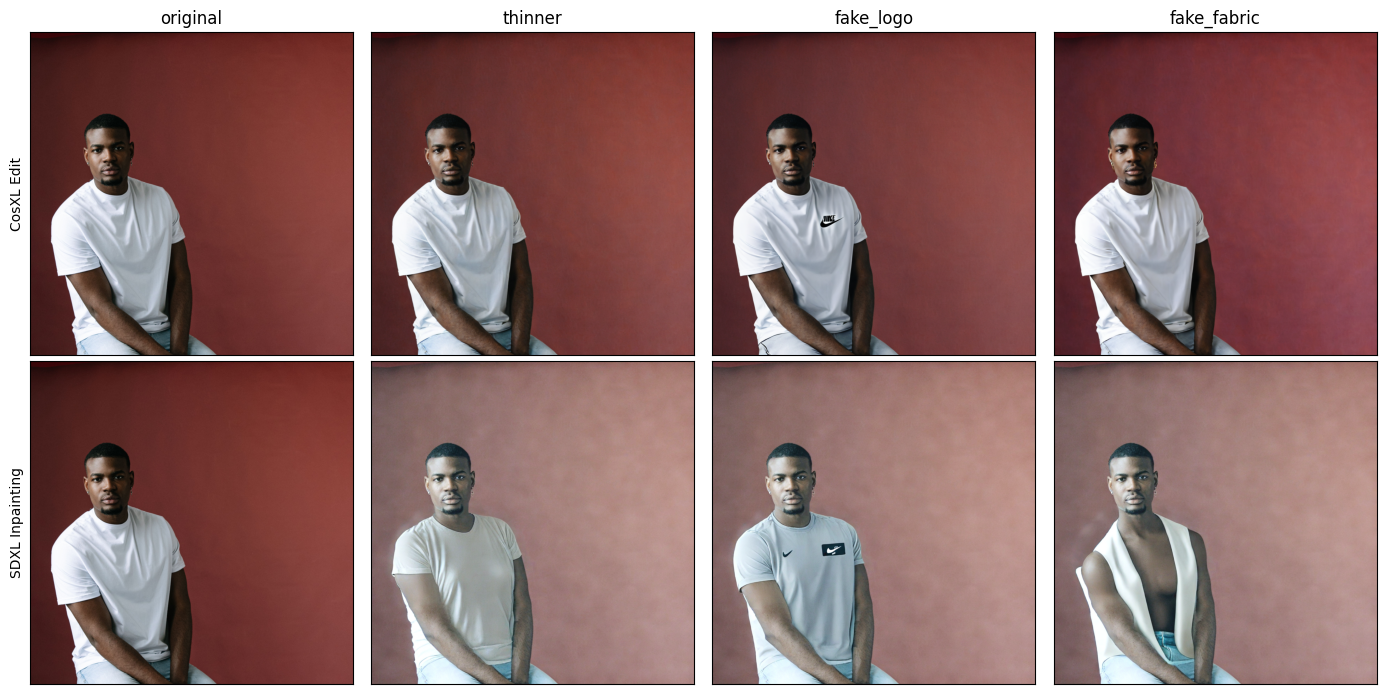

In [13]:
fig, ax = plt.subplots(2, 4, figsize=(14, 7))
for r, (label, f) in enumerate(folder.items()):
    ax[r, 0].imshow(originals[DARK]); ax[r, 0].set_ylabel(label)
    for c, k in enumerate(MISUSE, 1):
        ax[r, c].imshow(Image.open(f"p2_results/{f}/misuse_{k}.png"))
        if r == 0: ax[r, c].set_title(k)
    if r == 0: ax[r, 0].set_title("original")
for a in ax.flat: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.savefig("p2_results/misuse_grid.png", dpi=150); plt.show()

##Step 11 – Example edits figure

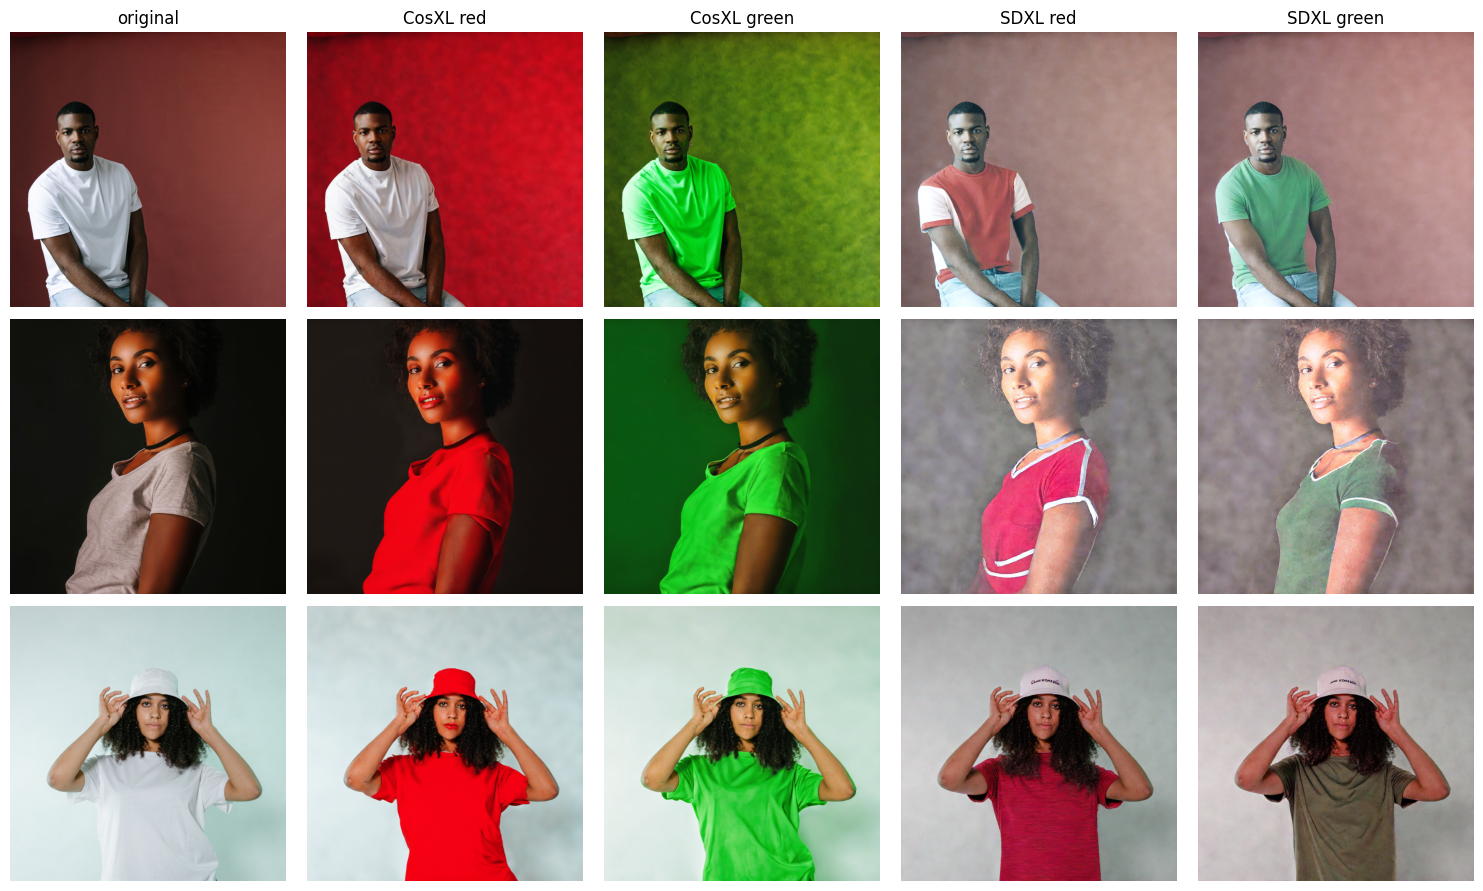

In [14]:
show = names[:3]
fig, ax = plt.subplots(len(show), 5, figsize=(15, 3 * len(show)))
for r, n in enumerate(show):
    s = os.path.splitext(n)[0]
    imgs = [originals[n]] + [Image.open(f"p2_results/{f}/{s}_{c}.png") for f in ["cosxl", "sdxl"] for c in COLOURS]
    for c, (im, t) in enumerate(zip(imgs, ["original", "CosXL red", "CosXL green", "SDXL red", "SDXL green"])):
        ax[r, c].imshow(im); ax[r, c].axis("off")
        if r == 0: ax[r, c].set_title(t)
plt.tight_layout(); plt.savefig("p2_results/examples.png", dpi=150); plt.show()

##Step 12 – Save and copy to Drive

In [13]:
df.to_csv("p2_results/pair2_all_edits.csv", index=False)
summary.to_csv("p2_results/pair2_summary.csv")
from google.colab import drive
drive.mount('/content/drive')
!mkdir -p /content/drive/MyDrive/COMP8410_pair2
!cp -r p2_photos p2_results /content/drive/MyDrive/COMP8410_pair2/

Mounted at /content/drive


In [ ]:
# ==============================================================================
# LIVE DEMO CELL – Pair 2: CosXL Edit vs SDXL Inpainting
# ==============================================================================
import random
import matplotlib.pyplot as plt

print("🎬 STARTING LIVE DEMO...")

DEMO_PHOTO  = random.choice(names)   # or pick one, e.g. "p04_dark.jpg"
LIVE        = True                   # True = edit live with a new colour; False = replay saved results (instant)
DEMO_COLOUR = "blue" if LIVE else "red"   # live: any colour NOT in the test; replay: "red" or "green"

orig, mask = originals[DEMO_PHOTO], masks[DEMO_PHOTO]
text = f"a photo of a person wearing a {DEMO_COLOUR} top"
results = {}

if LIVE:
    # ---------------- System A: CosXL Edit (instruction, no mask) ----------------
    from diffusers import StableDiffusionXLInstructPix2PixPipeline, EDMEulerScheduler, AutoencoderKL
    from huggingface_hub import hf_hub_download
    vae = AutoencoderKL.from_pretrained("madebyollin/sdxl-vae-fp16-fix", torch_dtype=torch.float16)
    cos = StableDiffusionXLInstructPix2PixPipeline.from_single_file(
        hf_hub_download("stabilityai/cosxl", "cosxl_edit.safetensors"),
        num_in_channels=8, is_cosxl_edit=True, vae=vae, torch_dtype=torch.float16).to(device)
    cos.scheduler = EDMEulerScheduler(sigma_min=0.002, sigma_max=120.0, sigma_data=1.0,
                                      prediction_type="v_prediction", sigma_schedule="exponential")
    g = torch.Generator(device).manual_seed(SEED); t0 = time.perf_counter()
    img = cos(prompt=f"make the top {DEMO_COLOUR}", image=orig, height=1024, width=1024, guidance_scale=7.0,
              image_guidance_scale=1.5, num_inference_steps=20, generator=g).images[0]
    results["CosXL Edit"] = (img, time.perf_counter() - t0)
    del cos, vae; gc.collect(); torch.cuda.empty_cache()

    # ---------------- System B: SDXL Inpainting (masked top only) ----------------
    from diffusers import AutoPipelineForInpainting
    inp = AutoPipelineForInpainting.from_pretrained(
        "diffusers/stable-diffusion-xl-1.0-inpainting-0.1", torch_dtype=torch.float16, variant="fp16").to(device)
    g = torch.Generator(device).manual_seed(SEED); t0 = time.perf_counter()
    img = inp(prompt=f"a photo of a person wearing a plain {DEMO_COLOUR} short-sleeve t-shirt",
              negative_prompt="tank top, sleeveless, vest, white",
              image=orig, mask_image=mask, height=1024, width=1024,
              guidance_scale=8.0, strength=1.0, num_inference_steps=20, generator=g).images[0]
    results["SDXL Inpainting"] = (img, time.perf_counter() - t0)
    del inp; gc.collect(); torch.cuda.empty_cache()
else:
    stem = os.path.splitext(DEMO_PHOTO)[0]
    for m, f in folder.items():
        results[m] = (Image.open(f"p2_results/{f}/{stem}_{DEMO_COLOUR}.png").convert("RGB"), None)

# ---------------- Show and score ----------------
before = clip_score(orig, text)
fig, ax = plt.subplots(1, 4, figsize=(17, 4.8))
ax[0].imshow(orig); ax[0].set_title(f"Original ({tone(DEMO_PHOTO)} skin)\n{DEMO_PHOTO}", fontsize=10)
ax[1].imshow(mask, cmap="gray"); ax[1].set_title("SDXL mask\n(white = only area it may change)", fontsize=10)
print(f"\nRequest: make the top {DEMO_COLOUR}  |  photo: {DEMO_PHOTO}\n")
for a, (m, (img, secs)) in zip(ax[2:], results.items()):
    after = clip_score(img, text); outside = outside_change(orig, img, mask)
    a.imshow(img)
    a.set_title(f"{m}\nmatch {after:.1f} ({after - before:+.1f}) · outside change {outside:.3f}", fontsize=10)
    print(f"  {m:16s} match {after:5.1f}  gain {after - before:+5.1f}  outside change {outside:.3f}"
          + (f"  time {secs:.1f}s" if secs else ""))
for a in ax: a.axis("off")
plt.suptitle(f"Request: “make the top {DEMO_COLOUR}”", fontweight="bold")
plt.tight_layout(); plt.show()

print("\nHow to read it:")
print("  • match / gain  – how well the edit fits the request (independent CLIP judge, higher = better)")
print("  • outside change – how much the face, body and background changed (LPIPS, lower = better)")
print("\n🎬 LIVE DEMO COMPLETE!")